# Practical 2: Factorial Calculation of N Numbers

### 1. Aim
To compute log-factorials across 3 independent tasks using Sequential execution, multiprocessing.Pool (3 workers), multiprocessing.Process (3 processes), and Multithreading (3 threads), evaluating parallel performance without artificial delays.

### 2. Algorithm / Explanation
1. Define 3 independent tasks calculating ln(n!) = sum(ln(i)).<br>2. Sequential: calculate the 3 tasks sequentially.<br>3. Pool: distribute tasks to 3 worker processes via `pool.map()`.<br>4. Process: spawn 3 explicit `mp.Process` workers and collect results with `mp.Queue`.<br>5. Thread: execute 3 concurrent `threading.Thread` instances.<br>6. Verify numerical results and compare execution times.

### 3. Python Implementation


In [1]:
"""
Practical 2: Program to calculate factorial of N numbers
Pattern: Calculation of ln(n!) for 3 independent tasks
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def factorial_task(n):
    # ln(n!) = sum(ln(1) + ln(2) + ... + ln(n))
    arr = np.arange(1, n + 1, dtype=np.float64)
    return float(np.sum(np.log(arr)))

def proc_worker(n, q):
    q.put(factorial_task(n))

def thread_worker(n, results, idx):
    results[idx] = factorial_task(n)

def main():
    print("=" * 60)
    print("Practical 2: Factorial of N Numbers")
    print("=" * 60)
    N = 40_000_000
    tasks = [N, N, N]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = factorial_task(tasks[0])
    r2 = factorial_task(tasks[1])
    r3 = factorial_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(factorial_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 independent processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for n in tasks:
        p = mp.Process(target=proc_worker, args=(n, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, n in enumerate(tasks):
        t = threading.Thread(target=thread_worker, args=(n, th_res, i))
        threads.append(t)
        t.start()
    for t in threads:
        t.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Sample: ln({N:,}!) = {seq_res[0]:.4e}")
    print(f"[Sequential] Time: {t_seq:.4f}s")
    print(f"[Pool]       Time: {t_pool:.4f}s")
    print(f"[Process]    Time: {t_proc:.4f}s")
    print(f"[Thread]     Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    plt.figure(figsize=(8, 5))
    bars = plt.bar(methods, times, color=colors)
    plt.title("Execution Time Comparison (Factorial of N Numbers)", fontsize=13)
    plt.ylabel("Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("02_factorial_time.png", dpi=150)
    plt.close()
    
    plt.figure(figsize=(8, 5))
    plt.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    plt.title("Speedup Comparison relative to Sequential", fontsize=13, fontweight='bold')
    plt.xlabel("Method", fontsize=11)
    plt.ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    plt.ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        plt.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.savefig("02_factorial_speedup.png", dpi=150)
    plt.close()
    print("Graphs saved as '02_factorial_time.png' and '02_factorial_speedup.png'.")

if __name__ == "__main__":
    main()


Practical 2: Factorial of N Numbers
Sample: ln(40,000,000!) = 6.6018e+08
[Sequential] Time: 1.0930s
[Pool]       Time: 1.0035s
[Process]    Time: 1.0827s
[Thread]     Time: 0.4486s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.0930 seconds      1.00x
Pool         1.0035 seconds      1.09x
Process      1.0827 seconds      1.01x
Thread       0.4486 seconds      2.44x
---------------------------------------------
Graphs saved as '02_factorial_time.png' and '02_factorial_speedup.png'.


### 4. Output Graphs

#### A. Execution Time Comparison
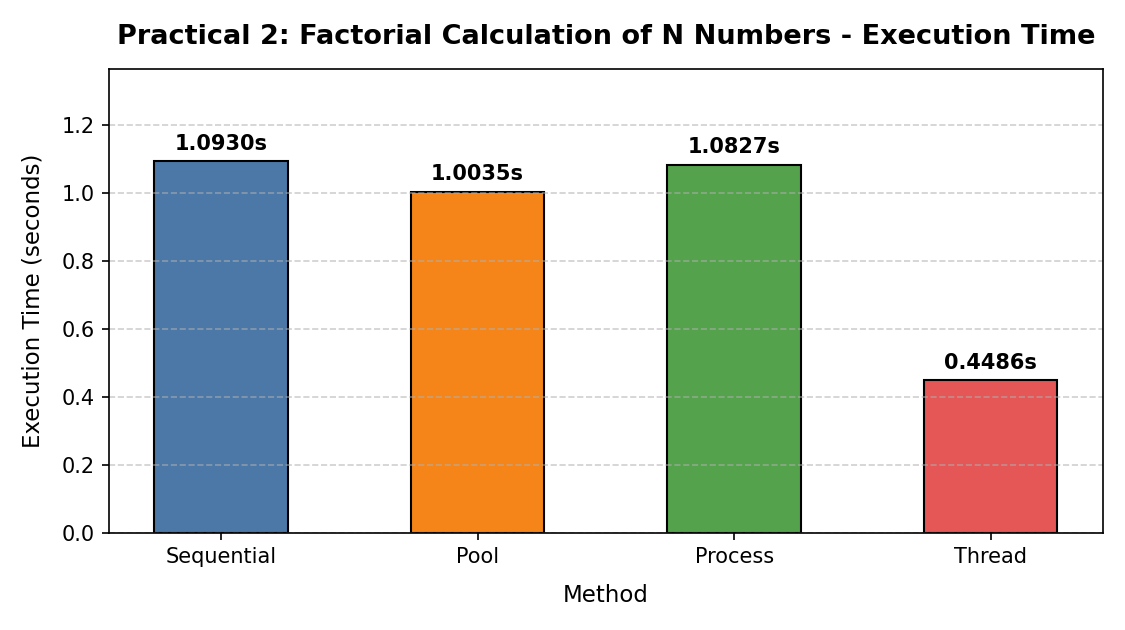

#### B. Speedup Comparison relative to Sequential
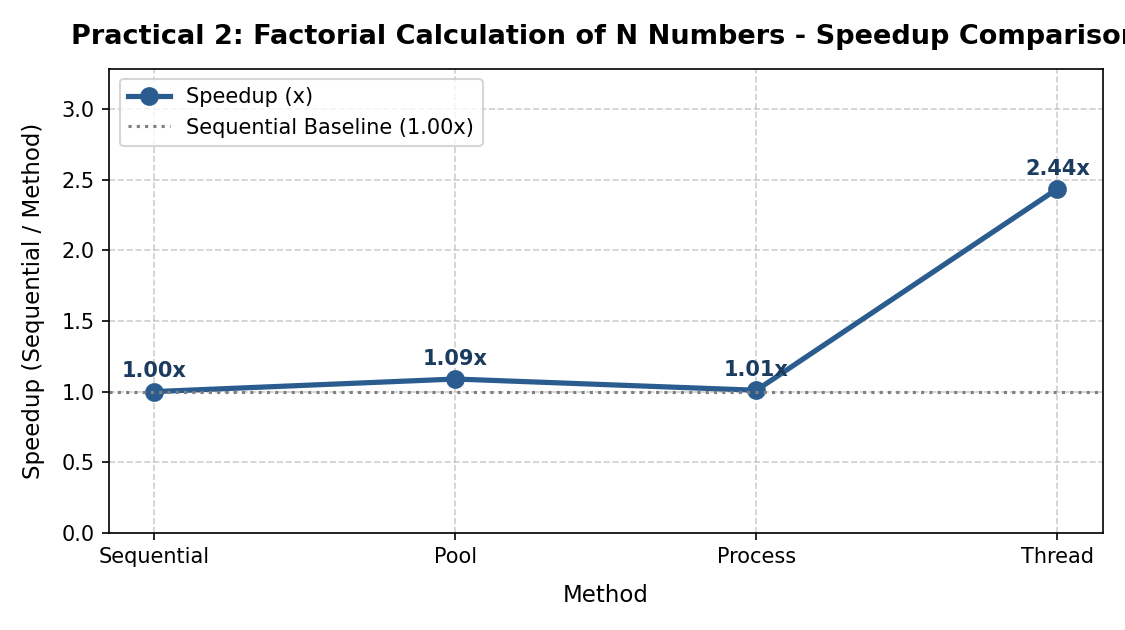
